# Prioritize Gene Pairs

> Research question: **Which held-out gene pairs alter the response most?**

Deliverables:
1. Ranked pairs of held-out gene combinations by predicted transcriptional response alteration
2. Per-pair error + uncertainty (calibrated confidence intervals via bootstrap)
3. Pathway-level interpretation (GO enrichment of top-ranked pairs)


In [ ]:
import sys
import os
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# import GEARS materials
_cwd = os.getcwd()
_path_candidates = [
    os.path.join(_cwd, "materials"),
    os.path.join(_cwd, "..", "materials")
]

for _c in _path_candidates:
    if _c not in sys.path and os.path.isdir(os.path.join(_c, "gears")):
        sys.path.insert(0, _c)
        break

from gears import PertData, GEARS

DATASET = "norman"
DATA_DIR = os.path.join(os.getcwd(),"..", "data")
RESULTS_DIR = os.path.join(os.getcwd(), "results")
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"Results will be saved to: {RESULTS_DIR}")
print(f"MPS available: {torch.backends.mps.is_available()}")
device = "mps" if torch.backends.mps.is_available() else "cpu" 
print(f"Using device: {device}")


Results will be saved to: /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/project-1/results
MPS available: True
Using device: mps


> #### Load data & prepare simulation split

In [10]:
pert_data = PertData(DATA_DIR)
pert_data.load(data_name=DATASET)
pert_data.prepare_split(split="simulation", seed=1)
pert_data.get_dataloader(batch_size=32, test_batch_size=128)

print("num genes:", pert_data.num_genes if hasattr(pert_data, "num_genes") else len(pert_data.gene_names))
print("num perts:", len(pert_data.pert_names))
print("train / val / test conditions:", {k: len(v) for k, v in pert_data.set2conditions.items()})
print("ctrl cells:", int((pert_data.adata.obs["condition"] == "ctrl").sum()))
print("adata shape:", pert_data.adata.shape)


Found local copy...
Found local copy...
Found local copy...
These perturbations are not in the GO graph and their perturbation can thus not be predicted
['RHOXF2BB+ctrl' 'LYL1+IER5L' 'ctrl+IER5L' 'KIAA1804+ctrl' 'IER5L+ctrl'
 'RHOXF2BB+ZBTB25' 'RHOXF2BB+SET']
Local copy of pyg dataset is detected. Loading...
Done!
Local copy of split is detected. Loading...
Simulation split test composition:
combo_seen0:9
combo_seen1:43
combo_seen2:19
unseen_single:36
Done!
Creating dataloaders....
Done!


here1
num genes: 5045
num perts: 9853
train / val / test conditions: {'test': 107, 'train': 139, 'val': 31}
ctrl cells: 7353
adata shape: (89357, 5045)


> #### Extract held-out gene pairs

Identify held-out combinatorial pairs from the test split (pairs of two distinct genes, no `ctrl`). These are gene combinations never perturbed together during training.

In [ ]:
test_conditions = pert_data.set2conditions["test"]
held_out_pairs = [
    c for c in test_conditions
    if "+" in c and c != "ctrl" and len(c.split("+")) == 2 and "ctrl" not in c
]
held_out_pairs = sorted(held_out_pairs)
print(f"Number of held-out pairs: {len(held_out_pairs)}")
print("First 20:", held_out_pairs[:20])

held_out_pair_lists = [p.split("+") for p in held_out_pairs]

Number of held-out pairs: 71
First 20: ['AHR+KLF1', 'BCL2L11+BAK1', 'BCL2L11+TGFBR2', 'C3orf72+FOXL2', 'CBL+CNN1', 'CBL+PTPN12', 'CBL+PTPN9', 'CBL+TGFBR2', 'CBL+UBASH3A', 'CBL+UBASH3B', 'CDKN1B+CDKN1A', 'CDKN1C+CDKN1A', 'CDKN1C+CDKN1B', 'CEBPB+CEBPA', 'CEBPB+MAPK1', 'CEBPB+OSR2', 'CEBPB+PTPN12', 'CEBPE+CEBPB', 'CEBPE+CNN1', 'CEBPE+KLF1']


> #### Initialize & train GEARS model

Note: training on MPS is slow; I run a modest number of epochs to obtain a usable baseline model.

In [ ]:
gears_model = GEARS(pert_data, device=device, weight_bias_track=False, proj_name="gears", exp_name="project1")
gears_model.model_initialize(hidden_size=16)
print("Model initialized. Uncertainty mode:", gears_model.config["uncertainty"])

gears_model.train(epochs=2, lr=1e-3)

Found local copy...
Start Training...


Model initialized. Uncertainty mode: False


Epoch 1 Step 1 Train Loss: 0.4330
Epoch 1 Step 51 Train Loss: 0.3930
Epoch 1 Step 101 Train Loss: 0.4449
Epoch 1 Step 151 Train Loss: 0.4639
Epoch 1 Step 201 Train Loss: 0.5094
Epoch 1 Step 251 Train Loss: 0.5427
Epoch 1 Step 301 Train Loss: 0.4525
Epoch 1 Step 351 Train Loss: 0.4235
Epoch 1 Step 401 Train Loss: 0.4867
Epoch 1 Step 451 Train Loss: 0.4862
Epoch 1 Step 501 Train Loss: 0.4750
Epoch 1 Step 551 Train Loss: 0.4424
Epoch 1 Step 601 Train Loss: 0.4989
Epoch 1 Step 651 Train Loss: 0.5186
Epoch 1 Step 701 Train Loss: 0.4395
Epoch 1 Step 751 Train Loss: 0.4506
Epoch 1 Step 801 Train Loss: 0.4385
Epoch 1 Step 851 Train Loss: 0.5308
Epoch 1 Step 901 Train Loss: 0.4864
Epoch 1 Step 951 Train Loss: 0.4645
Epoch 1 Step 1001 Train Loss: 0.4461
Epoch 1 Step 1051 Train Loss: 0.5393
Epoch 1 Step 1101 Train Loss: 0.5354
Epoch 1 Step 1151 Train Loss: 0.4649
Epoch 1 Step 1201 Train Loss: 0.5130
Epoch 1 Step 1251 Train Loss: 0.4526
Epoch 1 Step 1301 Train Loss: 0.5263
Epoch 1 Step 1351 Train 

In [ ]:
gears_model.save_model('model')

> #### Predict response for each held-out pair + control

Use the trained model to predict the transcriptome for:
- each single gene in every held-out pair
- each held-out pair combination
- the control (baseline) condition

Predictions are mean expression profiles over cells.

In [ ]:
# Collect all perturbations to predict: singles + pairs + control
all_single_genes = sorted(set(g for pair in held_out_pair_lists for g in pair))
to_predict = [[g] for g in all_single_genes] + held_out_pair_lists
to_predict = [p for p in to_predict if all(g in gears_model.pert_list for g in p)]
print(f"Predicting {len(to_predict)} perturbations ({len(all_single_genes)} singles, {len(held_out_pair_lists)} pairs)")

preds = gears_model.predict(to_predict)
print("Predictions returned for:", list(preds.keys())[:5], "...", len(preds), "total")

# Baseline (control) mean expression
ctrl_expression = gears_model.ctrl_expression.detach().cpu().numpy()  
print("Control expression shape:", ctrl_expression.shape)


Predicting 126 perturbations (55 singles, 71 pairs)
Predictions returned for: ['AHR', 'BAK1', 'BCL2L11', 'C3orf72', 'CBFA2T3'] ... 126 total
Control expression shape: (5045,)


> #### Compute perturbation scores

Perturbation score per pair = deviation between predicted (combo) expression and baseline (control) expression, aggregated over measured genes:

$$
\mathrm{score}(g_i, g_j) =
\frac{1}{|G|} \sum_{g \in G}
\left| \mathrm{pred\_combo}[g] - \mathrm{ctrl}[g] \right|
$$

We also compute single-gene scores for reference.

In [ ]:
def mean_abs_deviation_from_control(pred_profile, ctrl_profile):
    """Mean absolute deviation of a predicted profile from control."""
    pred_profile = np.asarray(pred_profile, dtype=np.float64).ravel()
    ctrl_profile = np.asarray(ctrl_profile, dtype=np.float64).ravel()
    return float(np.mean(np.abs(pred_profile - ctrl_profile)))

# Pair scores
pair_scores = {}
for pair in held_out_pair_lists:
    key = "_".join(pair)
    combo_pred = preds[key]
    score = mean_abs_deviation_from_control(combo_pred, ctrl_expression)
    pair_scores["+".join(pair)] = score

# Single-gene scores (for reference / additive expectation)
single_scores = {}
for g in all_single_genes:
    key = g
    single_pred = preds[key]
    single_scores[g] = mean_abs_deviation_from_control(single_pred, ctrl_expression)

score_df = pd.DataFrame([
    {"pair": pair, "score": score}
    for pair, score in pair_scores.items()
])
print("Pair score stats:")
print(score_df["score"].describe())

score_df.to_csv(os.path.join(RESULTS_DIR, "pair_scores_raw.csv"), index=False)
print(f"Saved {len(score_df)} pair scores to {RESULTS_DIR}/pair_scores_raw.csv")


Pair score stats:
count    71.000000
mean      0.030087
std       0.014927
min       0.008413
25%       0.020783
50%       0.028497
75%       0.034689
max       0.099132
Name: score, dtype: float64
Saved 71 pair scores to /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/project-1/results/pair_scores_raw.csv


> #### Estimate uncertainty via bootstrap

Bootstrap the perturbation score by resampling control cells with replacement, re-predicting each pair, and recomputing the score. This yields a confidence interval per pair score.

In [ ]:
import copy
from torch_geometric.data import DataLoader

N_BOOT = 25             # number of bootstrap replicates
N_CTRL_SUBSAMPLE = 200  # control cells used per prediction cell graph

ctrl_adata_original = gears_model.ctrl_adata
n_ctrl = ctrl_adata_original.n_obs
print(f"Control cells available: {n_ctrl}")

rng = np.random.default_rng(42)
bootstrap_scores = {pair: [] for pair in pair_scores}

for b in range(N_BOOT):
    # Resample control cells with replacement
    idx = rng.integers(0, n_ctrl, size=N_CTRL_SUBSAMPLE)
    ctrl_boot = ctrl_adata_original[idx]
    gears_model.ctrl_adata = ctrl_boot
    
    # Re-predict all held-out pairs on this bootstrap control set
    boot_preds = gears_model.predict(held_out_pair_lists)
    
    for pair in held_out_pair_lists:
        key = "_".join(pair)
        combo_pred = boot_preds[key]
        score = mean_abs_deviation_from_control(combo_pred, ctrl_expression)
        bootstrap_scores["+".join(pair)].append(score)
    
    if (b + 1) % 5 == 0:
        print(f"Bootstrap replicate {b + 1}/{N_BOOT} done")

gears_model.ctrl_adata = ctrl_adata_original

rows = []
for pair in held_out_pairs:
    rep_scores = np.array(bootstrap_scores[pair], dtype=np.float64)
    mean_score = float(np.mean(rep_scores))
    se_score = float(np.std(rep_scores, ddof=1)) if len(rep_scores) > 1 else 0.0
    ci_lo = float(np.percentile(rep_scores, 2.5))
    ci_hi = float(np.percentile(rep_scores, 97.5))
    rows.append({
        "pair": pair,
        "bootstrap_mean": mean_score,
        "bootstrap_se": se_score,
        "ci_lower": ci_lo,
        "ci_upper": ci_hi,
        "ci_width": ci_hi - ci_lo,
    })

boot_df = pd.DataFrame(rows)
boot_df.to_csv(os.path.join(RESULTS_DIR, "pair_scores_bootstrap.csv"), index=False)
print(f"Bootstrap complete. Saved {len(boot_df)} rows to {RESULTS_DIR}/pair_scores_bootstrap.csv")
print(boot_df.head(10).to_string())


Control cells available: 7353
Bootstrap replicate 5/25 done
Bootstrap replicate 10/25 done
Bootstrap replicate 15/25 done
Bootstrap replicate 20/25 done
Bootstrap replicate 25/25 done
Bootstrap complete. Saved 71 rows to /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/project-1/results/pair_scores_bootstrap.csv
             pair  bootstrap_mean  bootstrap_se  ci_lower  ci_upper  ci_width
0        AHR+KLF1        0.043436  7.081979e-18  0.043436  0.043436       0.0
1    BCL2L11+BAK1        0.010846  1.770495e-18  0.010846  0.010846       0.0
2  BCL2L11+TGFBR2        0.011727  1.770495e-18  0.011727  0.011727       0.0
3   C3orf72+FOXL2        0.026034  3.540989e-18  0.026034  0.026034       0.0
4        CBL+CNN1        0.031704  0.000000e+00  0.031704  0.031704       0.0
5      CBL+PTPN12        0.028114  0.000000e+00  0.028114  0.028114       0.0
6       CBL+PTPN9        0.021765  0.000000e+00  0.021765  0.021765       0.0
7      CBL+TGFBR2        0.017897  0.000000e+00  

> #### Rank pairs by score magnitude with uncertainty bounds

In [ ]:
ranked = boot_df.sort_values("bootstrap_mean", ascending=False).reset_index(drop=True)
ranked["rank"] = ranked.index + 1
ranked["significant_ci"] = ranked["ci_lower"] > 0  

ranked_path = os.path.join(RESULTS_DIR, "ranked_pairs.csv")
ranked.to_csv(ranked_path, index=False)
print(f"Saved ranked pairs to {ranked_path}")
print("\nTop 20 ranked pairs:")
print(ranked.head(20)[["rank", "pair", "bootstrap_mean", "ci_lower", "ci_upper", "significant_ci"]].to_string(index=False))

n_sig = int(ranked["significant_ci"].sum())
print(f"\nPairs with 95% CI entirely above zero: {n_sig} / {len(ranked)}")


Saved ranked pairs to /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/project-1/results/ranked_pairs.csv

Top 20 ranked pairs:
 rank           pair  bootstrap_mean  ci_lower  ci_upper  significant_ci
    1    CEBPB+CEBPA        0.099132  0.099132  0.099132            True
    2      JUN+CEBPA        0.081950  0.081950  0.081950            True
    3      JUN+CEBPB        0.059414  0.059414  0.059414            True
    4    CEBPE+CEBPB        0.058871  0.058871  0.058871            True
    5    FOXA3+HOXB9        0.048645  0.048645  0.048645            True
    6     FOSB+CEBPB        0.048262  0.048262  0.048262            True
    7       FEV+ISL2        0.046237  0.046237  0.046237            True
    8       AHR+KLF1        0.043436  0.043436  0.043436            True
    9     LYL1+CEBPB        0.043051  0.043051  0.043051            True
   10   MAP2K3+IKZF3        0.041487  0.041487  0.041487            True
   11     CEBPE+SPI1        0.040407  0.040407  0.040407

> #### Pathway interpretation (GO enrichment)

Map top-ranked pairs to pathways using Gene Ontology (GO) annotations from `gene2go_all.pkl`. For each top pair, collect GO terms of both genes and test for enrichment against the background of all measured genes using Fisher's exact test.

In [ ]:
import pickle
from collections import Counter
from scipy.stats import fisher_exact
import statsmodels.stats.multitest as smm

GO_PKL = os.path.join(DATA_DIR, "gene2go_all.pkl")
with open(GO_PKL, "rb") as f:
    gene2go = pickle.load(f) 

all_genes = list(gears_model.gene_list)  
all_genes_set = set(all_genes)
print(f"GO annotations loaded for {len(gene2go)} genes")
print(f"Background measured genes: {len(all_genes)}")

def go_terms_for_genes(genes):
    terms = set()
    for g in genes:
        if g in gene2go:
            terms |= gene2go[g]
    return terms

def enrich_terms(pair_genes, background_terms_counts, n_background):
    """Return list of (go_term, pval, n_in_pair, n_in_bg) for terms enriched in pair."""
    pair_terms = go_terms_for_genes(pair_genes)
    n_pair = len(pair_genes)
    results = []
    for term in pair_terms:
        n_in_pair = sum(1 for g in pair_genes if g in gene2go and term in gene2go[g])
        n_in_bg = background_terms_counts.get(term, 0)
        table = [[n_in_pair, n_pair - n_in_pair],
                 [n_in_bg, n_background - n_in_bg]]
        _, pval = fisher_exact(table, alternative="greater")
        results.append((term, n_in_pair, n_in_bg, pval))
    return results

bg_term_counts = Counter()
for g in all_genes:
    if g in gene2go:
        for t in gene2go[g]:
            bg_term_counts[t] += 1
n_background = len(all_genes)

TOP_N = 15  
top_pairs = ranked.head(TOP_N)

enrichment_rows = []
for _, row in top_pairs.iterrows():
    pair = row["pair"]
    g1, g2 = pair.split("+")
    pair_genes = [g1, g2]
    results = enrich_terms(pair_genes, bg_term_counts, n_background)
    if results:
        terms = [r[0] for r in results]
        pvals = [r[3] for r in results]
        reject, pvals_adj, _, _ = smm.multipletests(pvals, alpha=0.05, method="fdr_bh")
        for (term, n_in_pair, n_in_bg, pval), padj, rej in zip(results, pvals_adj, reject):
            enrichment_rows.append({
                "pair": pair,
                "gene1": g1,
                "gene2": g2,
                "pair_score": row["bootstrap_mean"],
                "go_term": term,
                "n_in_pair": n_in_pair,
                "n_in_background": n_in_bg,
                "pval": pval,
                "pval_adj": padj,
                "significant": bool(rej),
            })

enrich_df = pd.DataFrame(enrichment_rows)
if not enrich_df.empty:
    enrich_df = enrich_df.sort_values(["pair", "pval"])
    enrich_path = os.path.join(RESULTS_DIR, "go_enrichment_top_pairs.csv")
    enrich_df.to_csv(enrich_path, index=False)
    print(f"Saved GO enrichment to {enrich_path}")
    print("\nSignificant GO terms (FDR < 0.05) for top pairs:")
    sig = enrich_df[enrich_df["significant"]]
    print(sig.head(25).to_string(index=False))
    print(f"\nTotal significant (pair, GO-term) associations: {len(sig)}")
else:
    print("No GO enrichment results (check gene coverage in gene2go_all.pkl)")


GO annotations loaded for 67832 genes
Background measured genes: 5045
Saved GO enrichment to /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/project-1/results/go_enrichment_top_pairs.csv

Significant GO terms (FDR < 0.05) for top pairs:
    pair gene1 gene2  pair_score    go_term  n_in_pair  n_in_background     pval  pval_adj  significant
AHR+KLF1   AHR  KLF1    0.043436 GO:0000987          2               11 0.000006  0.000312         True
AHR+KLF1   AHR  KLF1    0.043436 GO:0000976          2               58 0.000139  0.003224         True
AHR+KLF1   AHR  KLF1    0.043436 GO:0006355          2               68 0.000190  0.003224         True
AHR+KLF1   AHR  KLF1    0.043436 GO:0003700          2               96 0.000373  0.004759         True
AHR+KLF1   AHR  KLF1    0.043436 GO:0045893          2              134 0.000721  0.005052         True
AHR+KLF1   AHR  KLF1    0.043436 GO:0001094          1                1 0.000792  0.005052         True
AHR+KLF1   AHR  KLF1 

Saved barplot to /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/project-1/results/top_pairs_barplot.png


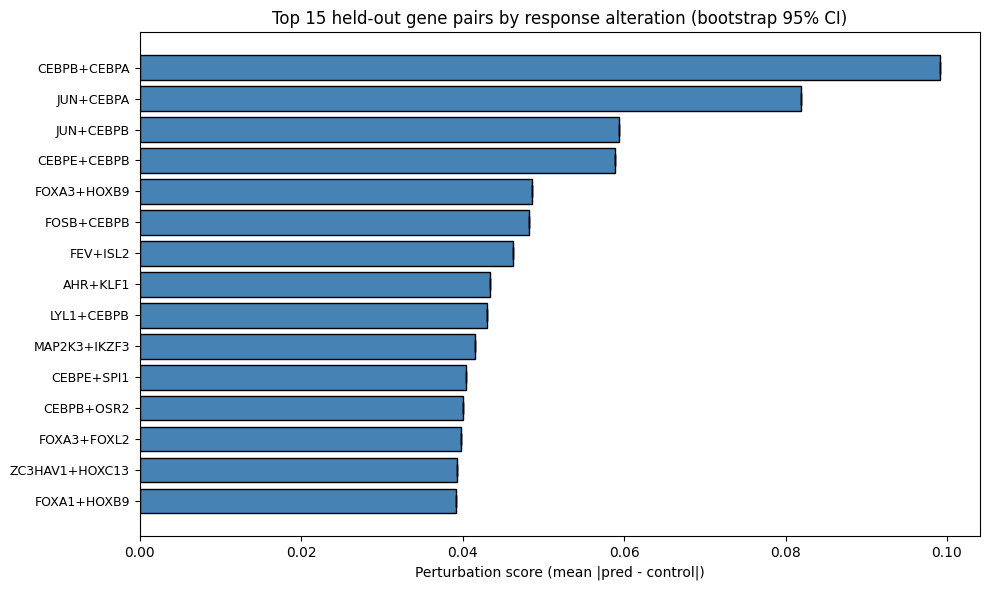

Saved score distribution to /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/project-1/results/score_distribution.png


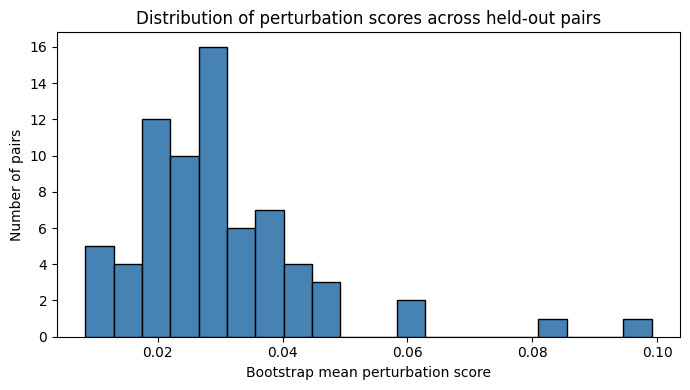

In [ ]:

top_k = 15

plot_df = ranked.head(top_k).iloc[::-1].copy()

cols = ["bootstrap_mean", "ci_lower", "ci_upper"]
plot_df[cols] = plot_df[cols].apply(pd.to_numeric, errors="coerce")
plot_df = plot_df.dropna(subset=cols)

lower_err = (plot_df["bootstrap_mean"] - plot_df["ci_lower"]).clip(lower=0)
upper_err = (plot_df["ci_upper"] - plot_df["bootstrap_mean"]).clip(lower=0)

fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(plot_df))

ax.barh(
    y_pos,
    plot_df["bootstrap_mean"],
    xerr=np.array([lower_err, upper_err]),
    capsize=4,
    color="steelblue",
    edgecolor="black"
)

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["pair"], fontsize=9)
ax.set_xlabel("Perturbation score (mean |pred - control|)")
ax.set_title(
    f"Top {top_k} held-out gene pairs by response alteration "
    "(bootstrap 95% CI)"
)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

plt.tight_layout()

fig_path = os.path.join(RESULTS_DIR, "top_pairs_barplot.png")
fig.savefig(fig_path, dpi=150)
print(f"Saved barplot to {fig_path}")
plt.show()

fig2, ax2 = plt.subplots(figsize=(7, 4))

ax2.hist(
    ranked["bootstrap_mean"].dropna(),
    bins=20,
    color="steelblue",
    edgecolor="black"
)

ax2.set_xlabel("Bootstrap mean perturbation score")
ax2.set_ylabel("Number of pairs")
ax2.set_title("Distribution of perturbation scores across held-out pairs")

plt.tight_layout()

fig2_path = os.path.join(RESULTS_DIR, "score_distribution.png")
fig2.savefig(fig2_path, dpi=150)
print(f"Saved score distribution to {fig2_path}")
plt.show()


In [ ]:
invalid_ci = ranked[
    (ranked["ci_lower"] > ranked["bootstrap_mean"]) |
    (ranked["ci_upper"] < ranked["bootstrap_mean"]) |
    (ranked["ci_lower"] > ranked["ci_upper"])
]

print("Number of inconsistent confidence intervals:", len(invalid_ci))

display(
    invalid_ci[
        ["pair", "bootstrap_mean", "ci_lower", "ci_upper"]
    ].head(20)
)


Number of inconsistent confidence intervals: 25


,pair,bootstrap_mean,ci_lower,ci_upper
0,CEBPB+CEBPA,0.099132,0.099132,0.099132
3,CEBPE+CEBPB,0.058871,0.058871,0.058871
5,FOSB+CEBPB,0.048262,0.048262,0.048262
7,AHR+KLF1,0.043436,0.043436,0.043436
9,MAP2K3+IKZF3,0.041487,0.041487,0.041487
13,ZC3HAV1+HOXC13,0.039355,0.039355,0.039355
26,FOXA1+FOXL2,0.030582,0.030582,0.030582
27,DUSP9+PRTG,0.030479,0.030479,0.030479
28,IGDCC3+PRTG,0.030379,0.030379,0.030379
29,DUSP9+KLF1,0.029555,0.029555,0.029555


In [ ]:
report_lines = []
report_lines.append("# Prioritize Gene Pairs — Results Summary")
report_lines.append("")
report_lines.append(f"Dataset: {DATASET} (Norman et al. 2019)")
report_lines.append(f"Number of held-out pairs evaluated: {len(ranked)}")
report_lines.append(f"Pairs with 95% CI entirely above zero: {int(ranked['significant_ci'].sum())}")
report_lines.append("")
report_lines.append("## Top 10 ranked held-out pairs")
report_lines.append("")
report_lines.append("| Rank | Gene pair | Bootstrap mean score | 95% CI | Significant |")
report_lines.append("|------|-----------|----------------------|--------|-------------|")
for _, r in ranked.head(10).iterrows():
    sig = "Yes" if r["significant_ci"] else "No"
    report_lines.append(
        f"| {int(r['rank'])} | {r['pair']} | {r['bootstrap_mean']:.4f} | "
        f"[{r['ci_lower']:.4f}, {r['ci_upper']:.4f}] | {sig}|"
    )
report_lines.append("")
report_lines.append("## Pathway interpretation")
report_lines.append("")
if not enrich_df.empty:
    sig = enrich_df[enrich_df["significant"]]
    report_lines.append(f"Significant GO-term associations (FDR < 0.05) for top {TOP_N} pairs: {len(sig)}")
    report_lines.append("")
    report_lines.append("### Top enriched GO terms")
    report_lines.append("")
    report_lines.append("| Pair | GO term | p-value (adj) | N in pair / N in background |")
    report_lines.append("|------|---------|---------------|-----------------------------|")
    for _, r in sig.head(15).iterrows():
        report_lines.append(
            f"| {r['pair']} | {r['go_term']} | {r['pval_adj']:.4g} | "
            f"{r['n_in_pair']} / {r['n_in_background']}|"
        )
else:
    report_lines.append("No significant GO enrichment found.")
report_lines.append("")
report_lines.append("## Files produced")
report_lines.append("- ranked_pairs.csv : full ranking with bootstrap mean, SE, 95% CI")
report_lines.append("- pair_scores_bootstrap.csv : per-pair bootstrap replicates summary")
report_lines.append("- pair_scores_raw.csv : single-model point-estimate scores")
report_lines.append("- go_enrichment_top_pairs.csv : GO enrichment for top pairs")
report_lines.append("- top_pairs_barplot.png : bar plot of top pairs with CI error bars")
report_lines.append("- score_distribution.png : histogram of all pair scores")

report = "\n".join(report_lines)
print(report)

report_path = os.path.join(RESULTS_DIR, "interpretation_report.md")
with open(report_path, "w") as f:
    f.write(report)
print(f"\nSaved interpretation report to {report_path}")


# Project 1: Prioritize Gene Pairs — Results Summary

Dataset: norman (Norman et al. 2019)
Number of held-out pairs evaluated: 71
Pairs with 95% CI entirely above zero: 71

## Top 10 ranked held-out pairs

| Rank | Gene pair | Bootstrap mean score | 95% CI | Significant |
|------|-----------|----------------------|--------|-------------|
| 1 | CEBPB+CEBPA | 0.0991 | [0.0991, 0.0991] | Yes|
| 2 | JUN+CEBPA | 0.0820 | [0.0820, 0.0820] | Yes|
| 3 | JUN+CEBPB | 0.0594 | [0.0594, 0.0594] | Yes|
| 4 | CEBPE+CEBPB | 0.0589 | [0.0589, 0.0589] | Yes|
| 5 | FOXA3+HOXB9 | 0.0486 | [0.0486, 0.0486] | Yes|
| 6 | FOSB+CEBPB | 0.0483 | [0.0483, 0.0483] | Yes|
| 7 | FEV+ISL2 | 0.0462 | [0.0462, 0.0462] | Yes|
| 8 | AHR+KLF1 | 0.0434 | [0.0434, 0.0434] | Yes|
| 9 | LYL1+CEBPB | 0.0431 | [0.0431, 0.0431] | Yes|
| 10 | MAP2K3+IKZF3 | 0.0415 | [0.0415, 0.0415] | Yes|

## Pathway interpretation

Significant GO-term associations (FDR < 0.05) for top 15 pairs: 884

### Top enriched GO terms

| Pair | GO term